# Exploratory Data Analysis — AirQualityHealth

## 1. Setup

Bagian ini menyiapkan library, path, dan pengaturan tampilan. Notebook diasumsikan dijalankan dari folder `notebooks/` atau dari root repository.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["figure.dpi"] = 110

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "figures"
SUMMARY_DIR = DATA_DIR / "eda_summary"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT.name)
print("Data dir     :", DATA_DIR.relative_to(PROJECT_ROOT).as_posix())
print("Figure dir   :", FIG_DIR.relative_to(PROJECT_ROOT).as_posix())
print("Summary dir  :", SUMMARY_DIR.relative_to(PROJECT_ROOT).as_posix())

Project root : Gelar Rasa
Data dir     : data
Figure dir   : figures
Summary dir  : data/eda_summary


## 2. Memuat Data

Memuat fact table hasil preprocessing dan dimensi pendukung.

In [2]:
aq = pd.read_parquet(DATA_DIR / "fact_air_quality.parquet")
health = pd.read_parquet(DATA_DIR / "fact_health.parquet")
dim_date = pd.read_csv(DATA_DIR / "dim_date.csv", parse_dates=["date"])
dim_time = pd.read_csv(DATA_DIR / "dim_time.csv")
dim_site = pd.read_csv(DATA_DIR / "dim_site.csv")
dim_hospital = pd.read_csv(DATA_DIR / "dim_hospital.csv")

health["date"] = pd.to_datetime(health["date"], errors="coerce")

print("fact_air_quality :", aq.shape)
print("fact_health      :", health.shape)
print("dim_date         :", dim_date.shape)
print("dim_time         :", dim_time.shape)
print("dim_site         :", dim_site.shape)
print("dim_hospital     :", dim_hospital.shape)

display(aq.head(3))
display(health.head(3))

fact_air_quality : (667981, 78)
fact_health      : (27491, 26)
dim_date         : (1019, 10)
dim_time         : (96, 5)
dim_site         : (27, 28)
dim_hospital     : (27, 7)


,measurement_id,sensor_id,site_key,source_file,timestamp_start,timestamp_end,date_key,time_key,time_resolution,qc_flag,is_qc_valid,is_timestamp_valid,data_quality_status,measurement_unit,pm25_raw,pm25_ug_m3,pm25_unit_status,pm25_candidate_ug_m3,pm25_is_invalid_code,pm25_imputed,pm25_was_imputed,pm25_is_outlier,pm10_raw,pm10_ug_m3,pm10_unit_status,pm10_candidate_ug_m3,pm10_is_invalid_code,pm10_imputed,pm10_was_imputed,pm10_is_outlier,so2_raw,so2_ug_m3,so2_unit_status,so2_is_invalid_code,so2_imputed,so2_was_imputed,so2_is_outlier,co_raw,co_ug_m3,co_unit_status,co_is_invalid_code,co_imputed,co_was_imputed,co_is_outlier,o3_raw,o3_ug_m3,o3_unit_status,o3_is_invalid_code,o3_imputed,o3_was_imputed,o3_is_outlier,no2_raw,no2_ug_m3,no2_unit_status,no2_is_invalid_code,no2_imputed,no2_was_imputed,no2_is_outlier,temperature_c,temperature_c_is_invalid_code,temperature_c_imputed,temperature_c_was_imputed,temperature_c_is_outlier,humidity_pct,humidity_pct_is_invalid_code,humidity_pct_imputed,humidity_pct_was_imputed,humidity_pct_is_outlier,wind_speed_ms,wind_speed_ms_is_invalid_code,wind_speed_ms_imputed,wind_speed_ms_was_imputed,wind_speed_ms_is_outlier,wind_direction_deg,wind_direction_deg_is_invalid_code,wind_direction_deg_imputed,wind_direction_deg_was_imputed,wind_direction_deg_is_outlier
0,MEAS-0000001,SENS-001,LOC-JKT-01,JKT-01_Gambir_AQMS.csv,2024-01-01 00:00:00,2024-01-01 01:00:00,"20,240,101.00",0.00,hourly,VALID,True,True,valid,ug_m3,45.74,45.74,valid_native,NaN,False,45.74,False,False,70.33,70.33,valid_native,NaN,False,70.33,False,False,22.24,22.24,valid_native,False,22.24,False,False,"1,631.80","1,631.80",valid_native,False,"1,631.80",False,False,29.06,29.06,valid_native,False,29.06,False,False,51.94,51.94,valid_native,False,51.94,False,False,25.70,False,25.70,False,False,87.50,False,87.50,False,False,2.20,False,2.20,False,False,315.00,False,315.00,False,False
1,MEAS-0000008,SENS-001,LOC-JKT-01,JKT-01_Gambir_AQMS.csv,2024-01-01 01:00:00,2024-01-01 02:00:00,"20,240,101.00",100.00,hourly,VALID,True,True,valid,ug_m3,43.52,43.52,valid_native,NaN,False,43.52,False,False,65.96,65.96,valid_native,NaN,False,65.96,False,False,25.15,25.15,valid_native,False,25.15,False,False,"1,288.80","1,288.80",valid_native,False,"1,288.80",False,False,32.50,32.50,valid_native,False,32.50,False,False,51.73,51.73,valid_native,False,51.73,False,False,24.40,False,24.40,False,False,91.40,False,91.40,False,True,2.80,False,2.80,False,False,315.00,False,315.00,False,False
2,MEAS-0000015,SENS-001,LOC-JKT-01,JKT-01_Gambir_AQMS.csv,2024-01-01 02:00:00,2024-01-01 03:00:00,"20,240,101.00",200.00,hourly,VALID,True,True,valid,ug_m3,46.27,46.27,valid_native,NaN,False,46.27,False,False,69.84,69.84,valid_native,NaN,False,69.84,False,False,25.08,25.08,valid_native,False,25.08,False,False,"1,536.60","1,536.60",valid_native,False,"1,536.60",False,False,34.14,34.14,valid_native,False,34.14,False,False,52.11,52.11,valid_native,False,52.11,False,False,24.80,False,24.80,False,False,85.40,False,85.40,False,False,3.80,False,3.80,False,False,30.00,False,30.00,False,False


,health_record_id,date_key,hospital_id,date,time_key,time_hour,dow,temp_c,dptp_c,rhum_pct,resp_admissions_under5,resp_admissions_over60,asthma_emergency_cases,copd_admissions,resp,cvd,death,data_quality_status,has_missing_outcome,resp_admissions_under5_is_outlier,resp_admissions_over60_is_outlier,asthma_emergency_cases_is_outlier,copd_admissions_is_outlier,resp_is_outlier,cvd_is_outlier,death_is_outlier
0,HLTH-000001,20240101,RS-XXX-01,2024-01-01,100,1.00,Monday,28.40,23.80,76.10,12.00,25.00,12.00,5.00,59.00,8.00,4.00,valid,False,False,False,False,False,False,False,False
1,HLTH-000002,20240102,RS-XXX-01,2024-01-02,200,2.00,Tuesday,28.70,23.90,75.00,13.00,22.00,6.00,6.00,60.00,13.00,1.00,valid,False,False,False,False,False,False,False,False
2,HLTH-000003,20240103,RS-XXX-01,2024-01-03,300,3.00,Wednesday,28.80,24.00,75.80,20.00,20.00,3.00,4.00,57.00,11.00,8.00,valid,False,False,False,False,False,False,False,False


In [3]:
dim_date_small = dim_date[[
    "date_key", "date", "year", "month", "month_name",
    "day", "day_name", "day_of_week", "is_weekend",
]].copy()
dim_date_small["month_start"] = dim_date_small["date"].dt.to_period("M").dt.to_timestamp()

dim_time_small = dim_time[["time_key", "hour"]].copy()

dim_site_small = dim_site[[
    "site_key", "station_code", "provinsi", "kota_kabupaten",
    "site_type", "region_group", "latitude_dd", "longitude_dd",
    "traffic_intensity_per_h", "distance_to_road_m", "baseline_pm25",
]].copy()

aq = (
    aq.merge(dim_date_small, on="date_key", how="left")
      .merge(dim_time_small, on="time_key", how="left")
      .merge(dim_site_small, on="site_key", how="left")
)

health = (
    health.merge(
        dim_date_small[["date_key", "year", "month", "month_name", "month_start"]],
        on="date_key", how="left",
    )
    .merge(
        dim_hospital[["hospital_id", "provinsi", "kota_kabupaten", "kelas_faskes", "kapasitas_tempat_tidur"]],
        on="hospital_id", how="left",
    )
)

n_raw = len(aq)
n_invalid_ts = int(aq["date"].isna().sum())
n_pre_period = int((aq["date"] < pd.Timestamp("2024-01-01")).sum())
n_raw_valid = int(aq["is_qc_valid"].sum())

print("Observasi AQMS mentah           :", f"{n_raw:,}")
print("  timestamp tidak valid         :", f"{n_invalid_ts:,}")
print("  sebelum 1 Jan 2024            :", f"{n_pre_period:,}")
print("  VALID sebelum filter          :", f"{n_raw_valid:,}")

aq = aq[aq["date"] >= pd.Timestamp("2024-01-01")].copy()
health = health[health["date"] >= pd.Timestamp("2024-01-01")].copy()

print("\nPeriode analisis: 1 Jan 2024 - 14 Okt 2026")
print("Observasi AQMS periode analisis :", f"{len(aq):,}")
print("Observasi health periode analisis:", f"{len(health):,}")
print("aq columns    :", aq.shape[1])
print("health columns:", health.shape[1])
print("Provinsi AQMS :", aq["provinsi"].nunique())
print("Provinsi health:", health["provinsi"].nunique())

Observasi AQMS mentah           : 667,981
  timestamp tidak valid         : 132
  sebelum 1 Jan 2024            : 5
  VALID sebelum filter          : 599,185



Periode analisis: 1 Jan 2024 - 14 Okt 2026
Observasi AQMS periode analisis : 667,844
Observasi health periode analisis: 27,486
aq columns    : 98
health columns: 34
Provinsi AQMS : 21
Provinsi health: 21


## 3. Kualitas Data dan Cakupan

Bagian ini memeriksa status QC, missing value, duplikasi, cakupan waktu, dan jumlah observasi valid per stasiun.

In [4]:
total_aq = len(aq)
valid_all = int(aq["is_qc_valid"].sum())
valid_pm = aq[(aq["is_qc_valid"] == True) & (aq["pm25_ug_m3"].notna())].copy()

print(f"Total observasi AQMS (periode analisis) : {total_aq:,}")
print(f"Observasi VALID dalam periode            : {valid_all:,} ({valid_all / total_aq:.1%})")
print(f"Observasi PM2.5 numerik VALID            : {len(valid_pm):,}")
print(f"Stasiun dengan PM2.5 valid  : {valid_pm['site_key'].nunique()}")
print(f"Provinsi dengan PM2.5 valid : {valid_pm['provinsi'].nunique()}")

qc_counts = aq["qc_flag"].value_counts(dropna=False).rename_axis("qc_flag").reset_index(name="count")
qc_counts["share"] = qc_counts["count"] / total_aq
display(qc_counts)

display(aq["data_quality_status"].value_counts(dropna=False).rename_axis("status").reset_index(name="count"))

Total observasi AQMS (periode analisis) : 667,844
Observasi VALID dalam periode            : 599,179 (89.7%)
Observasi PM2.5 numerik VALID            : 533,813
Stasiun dengan PM2.5 valid  : 24
Provinsi dengan PM2.5 valid : 18


,qc_flag,count,share
0,VALID,599179,0.90
1,SUSPECT,19722,0.03
2,MISSING,13675,0.02
3,CALIBRATING,8072,0.01
4,WARMUP,3764,0.01
5,PARSER_FAIL,3608,0.01
6,FATAL_ERR,3530,0.01
7,GARBAGE,3521,0.01
8,COMM_LOST,3422,0.01
9,CORRUPT,3403,0.01


,status,count
0,valid,599179
1,qc_nonvalid,27043
2,sentinel_or_invalid,17768
3,missing,14914
4,error_text,8940


In [5]:
missing = (
    aq.isna().mean()
    .sort_values(ascending=False)
    .head(20)
    .to_frame("missing_share")
)
display(missing)

print("Duplikasi measurement_id       :", int(aq["measurement_id"].duplicated().sum()))
print("Duplikasi health date+hospital :", int(health.duplicated(["date_key", "hospital_id"]).sum()))

,missing_share
pm10_candidate_ug_m3,0.90
pm25_candidate_ug_m3,0.90
pm25_ug_m3,0.17
pm10_ug_m3,0.16
pm25_imputed,0.14
pm10_imputed,0.13
so2_ug_m3,0.06
no2_ug_m3,0.06
o3_ug_m3,0.06
co_ug_m3,0.06


Duplikasi measurement_id       : 0
Duplikasi health date+hospital : 0


In [6]:
print("Rentang waktu AQMS   :", aq["timestamp_start"].min(), "->", aq["timestamp_start"].max())
print("Rentang waktu health :", health["date"].min(), "->", health["date"].max())
print("Jumlah stasiun       :", aq["site_key"].nunique())
print("Jumlah provinsi AQMS :", aq["provinsi"].nunique())
print("Jumlah rumah sakit   :", health["hospital_id"].nunique())
print("Jumlah provinsi health:", health["provinsi"].nunique())

coverage = (
    valid_pm.groupby(["station_code", "provinsi"])
    .size()
    .sort_values(ascending=False)
    .to_frame("n_valid_pm25")
)
display(coverage.head(10))
display(coverage.tail(5))

Rentang waktu AQMS   : 2024-01-01 00:00:00 -> 2026-10-14 23:11:22.750
Rentang waktu health : 2024-01-01 00:00:00 -> 2026-10-14 00:00:00
Jumlah stasiun       : 27
Jumlah provinsi AQMS : 21
Jumlah rumah sakit   : 27
Jumlah provinsi health: 21


,,n_valid_pm25
station_code,provinsi,
AQMS-PLB-01,Sumatera Selatan,27447
AQMS-IDP-01,Aceh,24322
AQMS-BGL-01,Bengkulu,24307
AQMS-KTB-01,Sumatera Barat,24305
AQMS-PKU-01,Riau,24300
AQMS-STG-01,Kalimantan Barat,24298
AQMS-YKY-01,D.I. Yogyakarta,24291
AQMS-MLG-01,Jawa Timur,24290
AQMS-PLU-01,Sulawesi Tengah,24290


,,n_valid_pm25
station_code,provinsi,
AQMS-JKT-03,DKI Jakarta,23470
AQMS-JKT-01,DKI Jakarta,23454
AQMS-SM2-01,Kalimantan Timur,20767
AQMS-MER-01,Papua Selatan,4891
AQMS-JMB-02,Jambi,121


In [7]:
unit_cols = [
    "pm25_unit_status", "pm10_unit_status",
    "so2_unit_status", "co_unit_status",
    "o3_unit_status", "no2_unit_status",
]
for col in unit_cols:
    print(f"\n{col}")
    display(aq[col].value_counts(dropna=False).rename_axis(col).reset_index(name="count"))

flag_summary = pd.DataFrame({
    "flag": [
        "pm25_was_imputed", "pm25_is_outlier",
        "pm10_was_imputed", "pm10_is_outlier",
        "temperature_c_was_imputed", "wind_speed_ms_was_imputed",
    ],
    "count": [
        int(aq["pm25_was_imputed"].sum()),
        int(aq["pm25_is_outlier"].sum()),
        int(aq["pm10_was_imputed"].sum()),
        int(aq["pm10_is_outlier"].sum()),
        int(aq["temperature_c_was_imputed"].sum()),
        int(aq["wind_speed_ms_was_imputed"].sum()),
    ],
})
display(flag_summary)


pm25_unit_status


,pm25_unit_status,count
0,valid_native,598180
1,unresolved,69664



pm10_unit_status


,pm10_unit_status,count
0,valid_native,598180
1,unresolved,69664



so2_unit_status


,so2_unit_status,count
0,valid_native,598180
1,valid_converted,69664


... (3 outputs left out)

,o3_unit_status,count
0,valid_native,598180
1,valid_converted,69664



no2_unit_status


,no2_unit_status,count
0,valid_native,598180
1,valid_converted,69664


,flag,count
0,pm25_was_imputed,20285
1,pm25_is_outlier,33990
2,pm10_was_imputed,20295
3,pm10_is_outlier,31378
4,temperature_c_was_imputed,18614
5,wind_speed_ms_was_imputed,18614


**Catatan kualitas data.** Sebanyak 132 rekaman memiliki timestamp tidak valid (`date_key` kosong, timestamp 1970) dan 5 rekaman valid berada pada 31 Desember 2023. Keduanya dikeluarkan dari periode analisis 1 Januari 2024–14 Oktober 2026; setelah filter tersisa 667.844 observasi AQMS dan 599.179 observasi VALID. Tiga stasiun tidak memiliki PM2.5/PM10 valid karena satuan ppm tidak dapat dikonversi secara pasti, sehingga analisis PM2.5 efektif mencakup 24 stasiun. Nilai yang diimputasi dan outlier tetap dipertahankan; keduanya hanya ditandai.

## 4. Analisis Univariat

Statistik deskriptif, distribusi, dan pemeriksaan nilai ekstrem untuk polutan, meteorologi, serta outcome kesehatan.

In [8]:
pollutants = {
    "pm25_ug_m3": "PM2.5",
    "pm10_ug_m3": "PM10",
    "so2_ug_m3": "SO2",
    "co_ug_m3": "CO",
    "o3_ug_m3": "O3",
    "no2_ug_m3": "NO2",
}

rows = []
for col, label in pollutants.items():
    s = aq.loc[(aq["is_qc_valid"] == True) & aq[col].notna(), col]
    rows.append({
        "parameter": label,
        "n": int(s.size),
        "mean": s.mean(),
        "std": s.std(),
        "min": s.min(),
        "q1": s.quantile(0.25),
        "median": s.median(),
        "q3": s.quantile(0.75),
        "p95": s.quantile(0.95),
        "max": s.max(),
        "skewness": s.skew(),
        "kurtosis": s.kurtosis(),
    })

desc = pd.DataFrame(rows).set_index("parameter")
desc.to_csv(SUMMARY_DIR / "descriptive_stats.csv")
display(desc)

,n,mean,std,min,q1,median,q3,p95,max,skewness,kurtosis
parameter,,,,,,,,,,,
PM2.5,533813,40.57,49.99,2.00,18.01,28.17,48.85,109.80,"1,620.50",8.49,119.92
PM10,533813,58.77,65.26,4.50,26.40,41.60,74.00,142.40,"2,102.05",7.55,97.87
SO2,599179,10.06,6.93,1.00,5.96,8.31,10.50,26.57,45.67,2.22,5.08
CO,599179,636.48,559.45,80.00,346.90,400.00,651.12,"1,844.00","8,256.30",3.55,26.29
O3,599179,20.22,15.00,2.00,9.70,14.50,26.97,49.10,106.04,1.82,3.87
NO2,599179,26.02,14.88,2.00,17.20,20.00,29.44,61.93,85.00,1.74,2.25


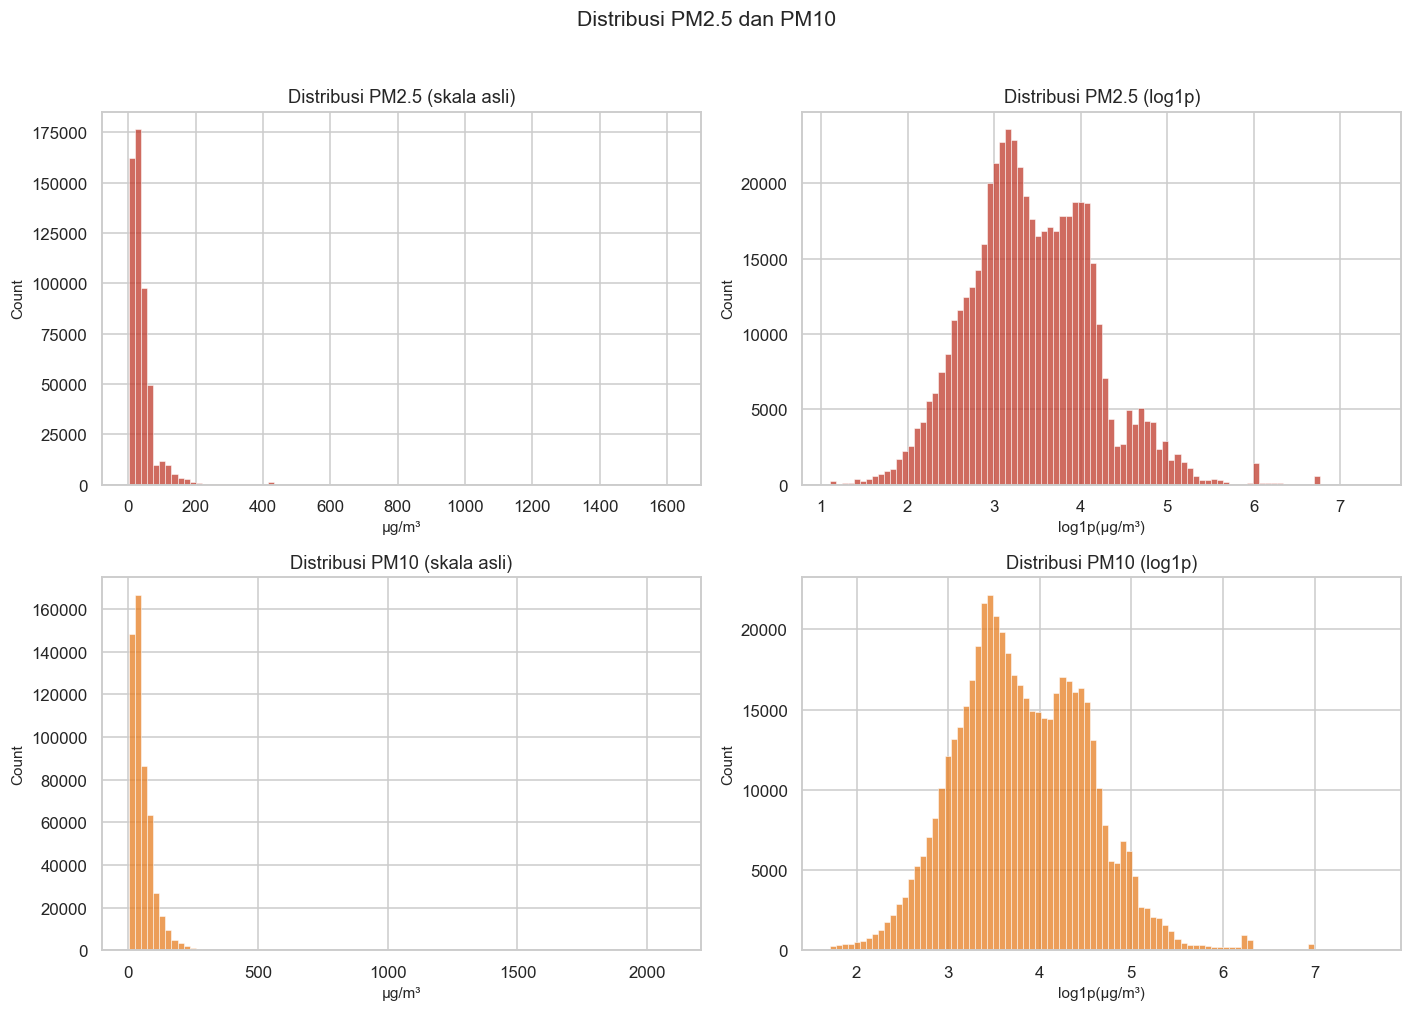

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(valid_pm["pm25_ug_m3"], bins=90, ax=axes[0, 0], color="#c0392b")
axes[0, 0].set_title("Distribusi PM2.5 (skala asli)")
axes[0, 0].set_xlabel("µg/m³")

sns.histplot(np.log1p(valid_pm["pm25_ug_m3"]), bins=90, ax=axes[0, 1], color="#c0392b")
axes[0, 1].set_title("Distribusi PM2.5 (log1p)")
axes[0, 1].set_xlabel("log1p(µg/m³)")

sns.histplot(valid_pm["pm10_ug_m3"].dropna(), bins=90, ax=axes[1, 0], color="#e67e22")
axes[1, 0].set_title("Distribusi PM10 (skala asli)")
axes[1, 0].set_xlabel("µg/m³")

sns.histplot(np.log1p(valid_pm["pm10_ug_m3"].dropna()), bins=90, ax=axes[1, 1], color="#e67e22")
axes[1, 1].set_title("Distribusi PM10 (log1p)")
axes[1, 1].set_xlabel("log1p(µg/m³)")

fig.suptitle("Distribusi PM2.5 dan PM10", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_distribusi_pm25.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

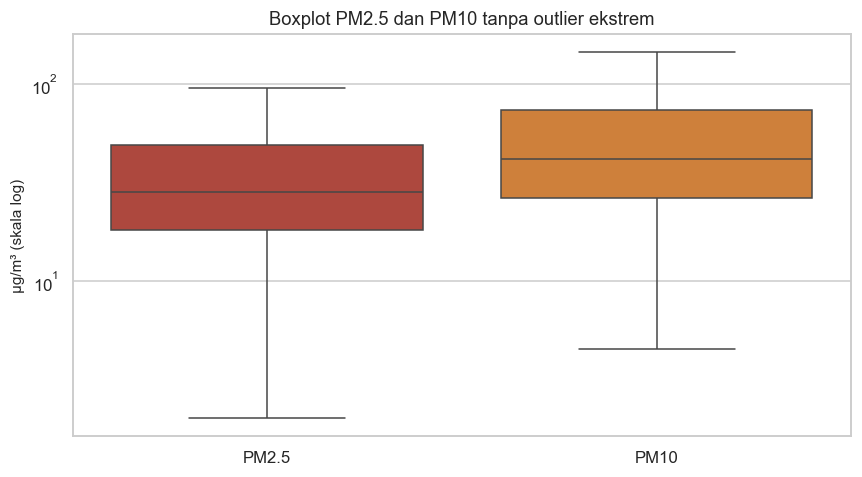

In [10]:
box_data = valid_pm[["pm25_ug_m3", "pm10_ug_m3"]].rename(columns={
    "pm25_ug_m3": "PM2.5",
    "pm10_ug_m3": "PM10",
})

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=box_data, ax=ax, showfliers=False, palette=["#c0392b", "#e67e22"])
ax.set_yscale("log")
ax.set_ylabel("µg/m³ (skala log)")
ax.set_title("Boxplot PM2.5 dan PM10 tanpa outlier ekstrem")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_boxplot_pm.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

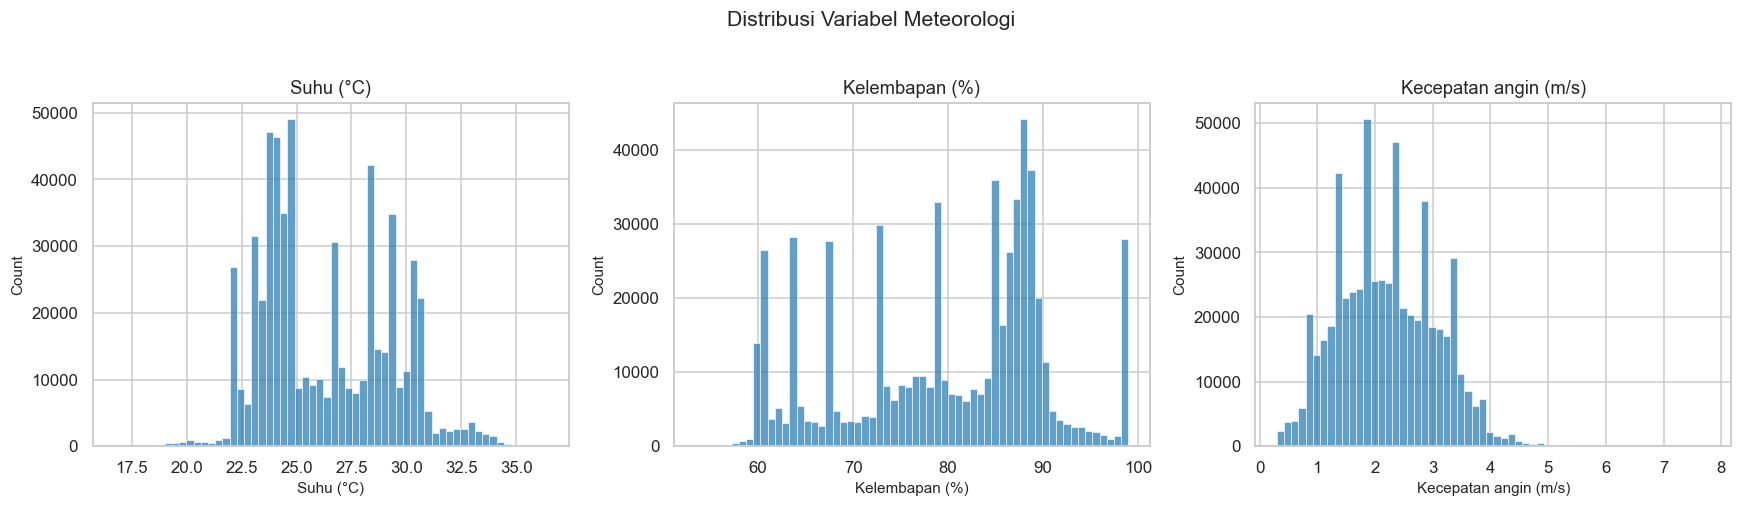

In [11]:
meteo_cols = [
    ("temperature_c", "Suhu (°C)"),
    ("humidity_pct", "Kelembapan (%)"),
    ("wind_speed_ms", "Kecepatan angin (m/s)"),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, label) in zip(axes, meteo_cols):
    s = aq.loc[aq["is_qc_valid"] == True, col].dropna()
    sns.histplot(s, bins=60, ax=ax, color="#2c7fb8")
    ax.set_title(label)
    ax.set_xlabel(label)
fig.suptitle("Distribusi Variabel Meteorologi", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_distribusi_meteo.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

In [12]:
outcomes = [
    "resp", "resp_admissions_under5", "resp_admissions_over60",
    "asthma_emergency_cases", "copd_admissions", "cvd", "death",
]

health_summary = health[outcomes].agg(["sum", "mean", "median", "max"]).T
health_summary["share_of_resp"] = health_summary["sum"] / health_summary.loc["resp", "sum"]
health_summary.to_csv(SUMMARY_DIR / "health_summary.csv")
display(health_summary)

,sum,mean,median,max,share_of_resp
resp,"733,191.00",26.68,21.00,307.00,1.00
resp_admissions_under5,"186,167.00",6.77,5.00,114.00,0.25
resp_admissions_over60,"225,117.00",8.19,6.00,127.00,0.31
asthma_emergency_cases,"132,825.00",4.83,4.00,64.00,0.18
copd_admissions,"109,329.00",3.98,3.00,76.00,0.15
cvd,"206,668.00",7.52,7.00,61.00,0.28
death,"54,630.00",1.99,2.00,24.00,0.07


## 5. Pola Temporal

Analisis temporal mencakup tren bulanan, profil bulan kalender, perbandingan Januari–September, pola harian, pola jam, dan heatmap jam × hari.

,month_start,pm25,pm10,n
0,2024-01-01,25.41,38.37,16137
1,2024-02-01,24.21,36.57,14968
2,2024-03-01,24.23,36.61,16129
3,2024-04-01,25.72,38.81,15562
4,2024-05-01,28.07,42.31,16085


,month_start,pm25,pm10,n
29,2026-06-01,31.61,47.82,15574
30,2026-07-01,43.97,65.13,15832
31,2026-08-01,69.95,96.40,15757
32,2026-09-01,107.07,140.59,16934
33,2026-10-01,155.52,200.48,7833


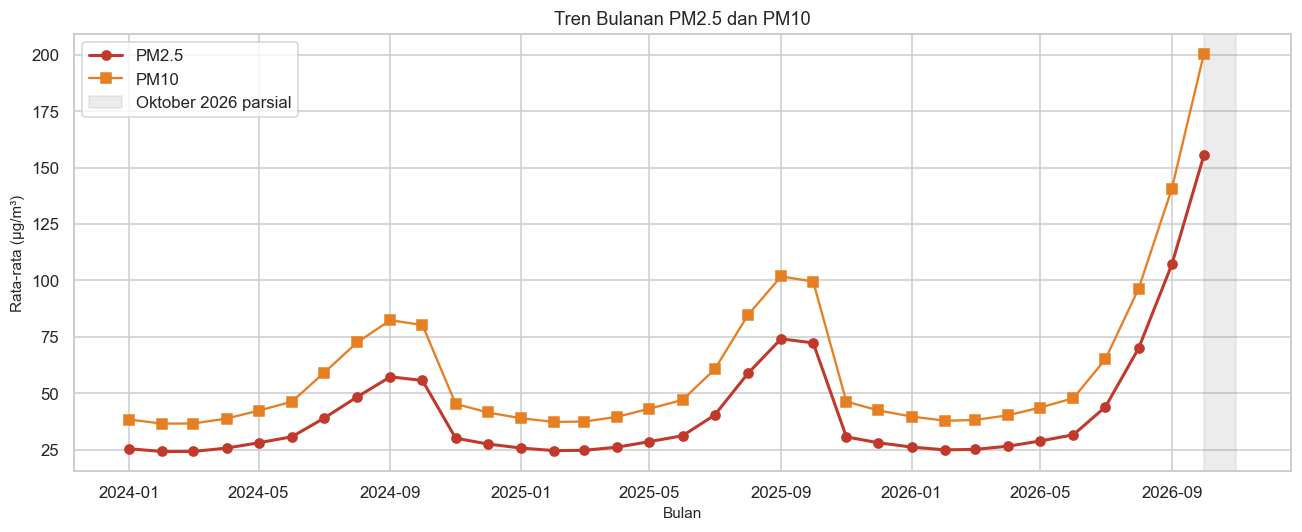

In [13]:
monthly = (
    valid_pm.groupby("month_start")
    .agg(
        pm25=("pm25_ug_m3", "mean"),
        pm10=("pm10_ug_m3", "mean"),
        n=("pm25_ug_m3", "size"),
    )
    .reset_index()
)
monthly.to_csv(SUMMARY_DIR / "bulanan_summary.csv", index=False)
display(monthly.head())
display(monthly.tail())

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly["month_start"], monthly["pm25"], marker="o", linewidth=2, label="PM2.5", color="#c0392b")
ax.plot(monthly["month_start"], monthly["pm10"], marker="s", linewidth=1.5, label="PM10", color="#e67e22")
ax.axvspan(pd.Timestamp("2026-10-01"), pd.Timestamp("2026-10-31"), color="grey", alpha=0.15, label="Oktober 2026 parsial")
ax.set_title("Tren Bulanan PM2.5 dan PM10")
ax.set_xlabel("Bulan")
ax.set_ylabel("Rata-rata (µg/m³)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_tren_bulanan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

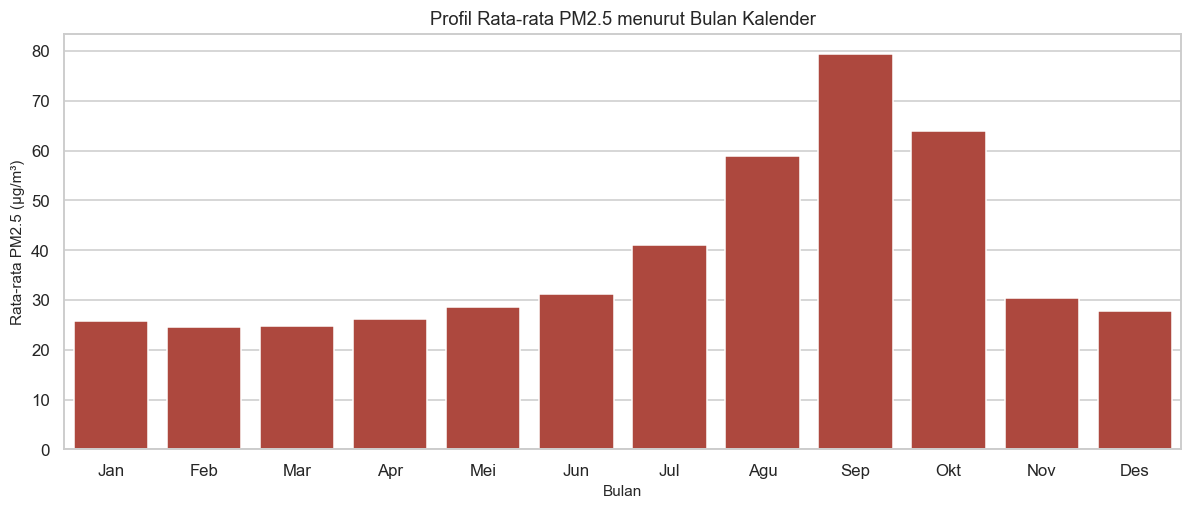

,month,pm25,pm10,n,bulan
0,1.00,25.78,39.01,48286,Jan
1,2.00,24.58,37.23,43940,Feb
2,3.00,24.69,37.42,48232,Mar
3,4.00,26.14,39.55,46624,Apr
4,5.00,28.50,43.06,48112,Mei
5,6.00,31.17,47.05,46633,Jun
6,7.00,41.08,61.60,47509,Jul
7,8.00,58.99,84.48,47526,Agu
8,9.00,79.47,108.22,50842,Sep
9,10.00,64.01,89.89,35120,Okt


In [14]:
full_months = valid_pm[~((valid_pm["year"] == 2026) & (valid_pm["month"] == 10))].copy()

bulan_id = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
    7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des",
}

calendar = (
    full_months.groupby("month")
    .agg(pm25=("pm25_ug_m3", "mean"), pm10=("pm10_ug_m3", "mean"), n=("pm25_ug_m3", "size"))
    .reset_index()
    .sort_values("month")
)
calendar["bulan"] = calendar["month"].map(bulan_id)

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.barplot(data=calendar, x="bulan", y="pm25", ax=ax, color="#c0392b")
ax.set_title("Profil Rata-rata PM2.5 menurut Bulan Kalender")
ax.set_xlabel("Bulan")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_profil_bulanan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

display(calendar)

In [15]:
jan_sep = (
    valid_pm[valid_pm["month"] <= 9]
    .groupby("year")
    .agg(
        pm25=("pm25_ug_m3", "mean"),
        pm10=("pm10_ug_m3", "mean"),
        n=("pm25_ug_m3", "size"),
    )
    .reset_index()
)
jan_sep["pm25_growth_vs_prev"] = jan_sep["pm25"].pct_change()
jan_sep.to_csv(SUMMARY_DIR / "jan_sep_summary.csv", index=False)
display(jan_sep)

,year,pm25,pm10,n,pm25_growth_vs_prev
0,"2,024.00",33.90,50.65,143262,NaN
1,"2,025.00",37.52,55.01,142175,0.11
2,"2,026.00",43.33,61.86,142267,0.15


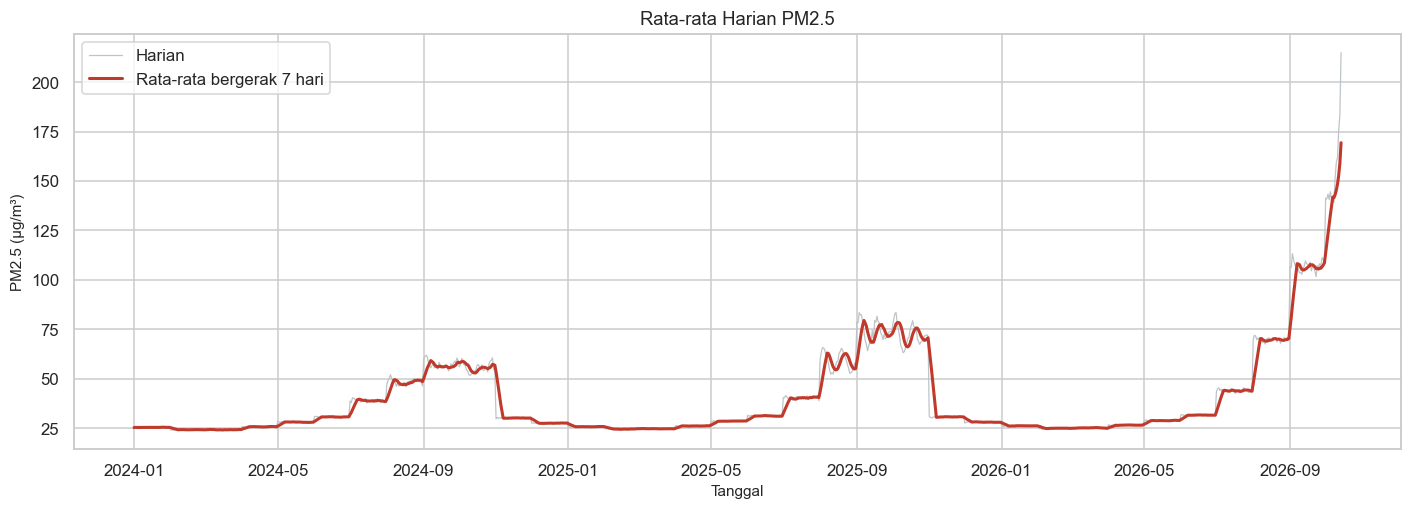

In [16]:
daily = (
    valid_pm.groupby("date")
    .agg(pm25=("pm25_ug_m3", "mean"), n=("pm25_ug_m3", "size"))
    .reset_index()
    .sort_values("date")
)
daily["rolling_7d"] = daily["pm25"].rolling(7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(daily["date"], daily["pm25"], color="#bdc3c7", linewidth=0.8, label="Harian")
ax.plot(daily["date"], daily["rolling_7d"], color="#c0392b", linewidth=2, label="Rata-rata bergerak 7 hari")
ax.set_title("Rata-rata Harian PM2.5")
ax.set_xlabel("Tanggal")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "06_harian.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

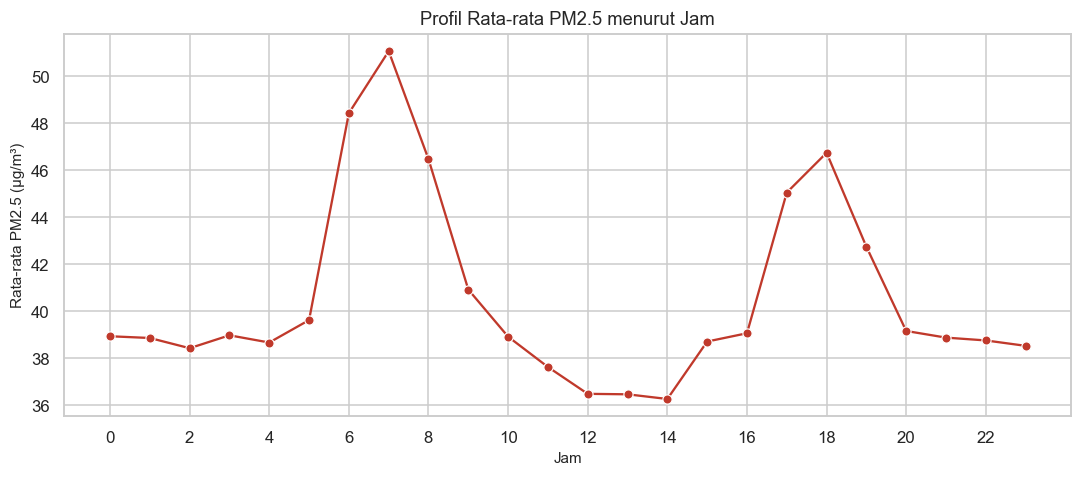

,hour,pm25,n
7,7.00,51.07,22262
6,6.00,48.43,22266
18,18.00,46.74,22208
8,8.00,46.47,22243
17,17.00,45.05,22177


In [17]:
hourly = valid_pm.groupby("hour").agg(pm25=("pm25_ug_m3", "mean"), n=("pm25_ug_m3", "size")).reset_index()

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=hourly, x="hour", y="pm25", marker="o", ax=ax, color="#c0392b")
ax.set_title("Profil Rata-rata PM2.5 menurut Jam")
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.set_xticks(range(0, 24, 2))
fig.tight_layout()
fig.savefig(FIG_DIR / "07_pola_jam.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

display(hourly.sort_values("pm25", ascending=False).head(5))

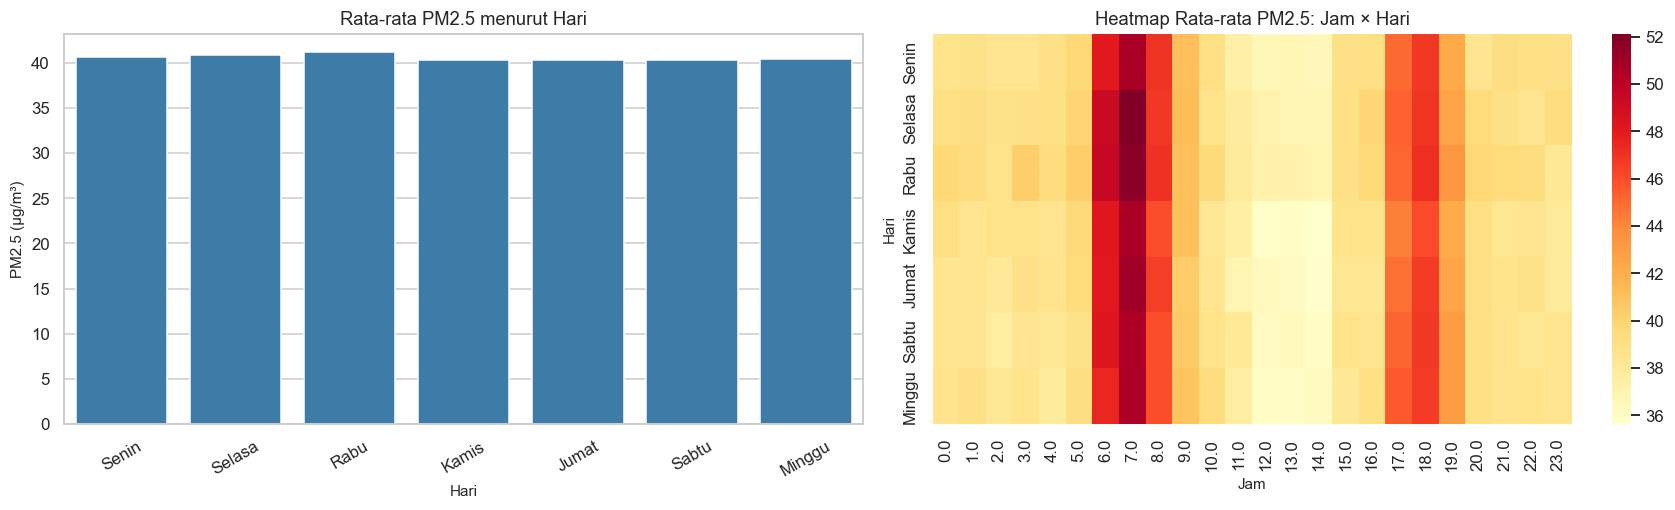

In [18]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_id = {
    "Monday": "Senin", "Tuesday": "Selasa", "Wednesday": "Rabu",
    "Thursday": "Kamis", "Friday": "Jumat", "Saturday": "Sabtu", "Sunday": "Minggu",
}

dow = (
    valid_pm.groupby("day_name")["pm25_ug_m3"]
    .mean()
    .reindex(day_order)
)
dow.index = [day_id[d] for d in dow.index]

heat = (
    valid_pm.pivot_table(index="day_name", columns="hour", values="pm25_ug_m3", aggfunc="mean")
    .reindex(day_order)
)
heat.index = [day_id[d] for d in heat.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.barplot(x=dow.index, y=dow.values, ax=axes[0], color="#2c7fb8")
axes[0].set_title("Rata-rata PM2.5 menurut Hari")
axes[0].set_xlabel("Hari")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].tick_params(axis="x", rotation=30)

sns.heatmap(heat, cmap="YlOrRd", ax=axes[1])
axes[1].set_title("Heatmap Rata-rata PM2.5: Jam × Hari")
axes[1].set_xlabel("Jam")
axes[1].set_ylabel("Hari")

fig.tight_layout()
fig.savefig(FIG_DIR / "08_heatmap_jam_hari.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

In [19]:
oct2026 = valid_pm[(valid_pm["year"] == 2026) & (valid_pm["month"] == 10)]
oct_full = valid_pm[(valid_pm["month"] == 10) & (valid_pm["year"] < 2026)]

print("Oktober 2026 (parsial)")
print("  n     :", len(oct2026))
print("  tanggal:", oct2026["date"].min(), "->", oct2026["date"].max())
print("  mean  :", round(oct2026["pm25_ug_m3"].mean(), 2))

print("\nOktober penuh 2024-2025")
print("  n     :", len(oct_full))
print("  mean  :", round(oct_full["pm25_ug_m3"].mean(), 2))

Oktober 2026 (parsial)
  n     : 7833
  tanggal: 2026-10-01 00:00:00 -> 2026-10-14 00:00:00
  mean  : 155.52

Oktober penuh 2024-2025
  n     : 35120
  mean  : 64.01


**Catatan temporal.** Pola bulanan menunjukkan kenaikan tajam mulai Juli, puncak pada September, dan penurunan pada November. Oktober 2026 hanya mencakup 1–14 Oktober, sehingga tidak dibandingkan langsung dengan bulan penuh. Pola jam lebih menonjol daripada pola hari dalam seminggu.

## 6. Pola Spasial

Ringkasan level stasiun, provinsi, tipe lokasi, dan sebaran geografis.

In [20]:
station_summary = (
    valid_pm.groupby(["site_key", "station_code", "provinsi", "site_type"])
    .agg(
        n=("pm25_ug_m3", "size"),
        mean=("pm25_ug_m3", "mean"),
        median=("pm25_ug_m3", "median"),
        p95=("pm25_ug_m3", lambda s: s.quantile(0.95)),
        max=("pm25_ug_m3", "max"),
    )
    .reset_index()
    .sort_values("mean", ascending=False)
)
station_summary.to_csv(SUMMARY_DIR / "stasiun_summary.csv", index=False)
display(station_summary.head(10))
display(station_summary.tail(5))

,site_key,station_code,provinsi,site_type,n,mean,median,p95,max
18,LOC-PLB-01,AQMS-PLB-01,Sumatera Selatan,Peatland Buffer / Urban Artery,27447,89.43,72.20,187.70,285.10
20,LOC-SM2-01,AQMS-SM2-01,Kalimantan Timur,Industrial & Deforestation Buffer,20767,78.84,47.81,256.45,580.00
9,LOC-JMB-02,AQMS-JMB-02,Jambi,Peatland & Plantation Hinterland,121,68.60,68.58,75.75,78.50
11,LOC-KTG-01,AQMS-KTG-01,Kalimantan Tengah,Urban Background,23506,61.23,24.81,129.80,"1,620.50"
12,LOC-KTG-02,AQMS-KTG-02,Kalimantan Tengah,Peatland Boundary,23524,60.84,24.87,129.63,"1,530.69"
6,LOC-JKT-02,AQMS-JKT-02,DKI Jakarta,Industrial Perimeter,23480,60.07,58.92,74.12,86.79
7,LOC-JKT-03,AQMS-JKT-03,DKI Jakarta,Traffic / Roadside,23470,54.06,52.95,67.99,80.15
5,LOC-JKT-01,AQMS-JKT-01,DKI Jakarta,Urban Background,23454,48.09,46.99,61.97,72.99
3,LOC-BTM-01,AQMS-BTM-01,Kepulauan Riau,Industrial Perimeter / Maritime,24277,47.58,38.50,98.50,191.50
17,LOC-PKU-01,AQMS-PKU-01,Riau,Peatland Buffer / Urban,24300,47.09,35.30,110.60,201.30


,site_key,station_code,provinsi,site_type,n,mean,median,p95,max
21,LOC-SRG-01,AQMS-SRG-01,Papua Barat Daya,Coastal / Regional Background,24277,18.37,17.90,29.22,58.60
13,LOC-MER-01,AQMS-MER-01,Papua Selatan,Coastal / Remote Savanna,4891,16.08,16.05,22.12,29.18
1,LOC-BGR-01,AQMS-BGR-01,Jawa Barat,Regional / Clean Background,23688,13.23,13.10,17.13,21.65
19,LOC-PLU-01,AQMS-PLU-01,Sulawesi Tengah,Regional / Clean Background,24290,11.26,11.00,18.30,91.50
4,LOC-IDP-01,AQMS-IDP-01,Aceh,Regional / Clean Background,24322,9.34,8.90,16.30,24.50


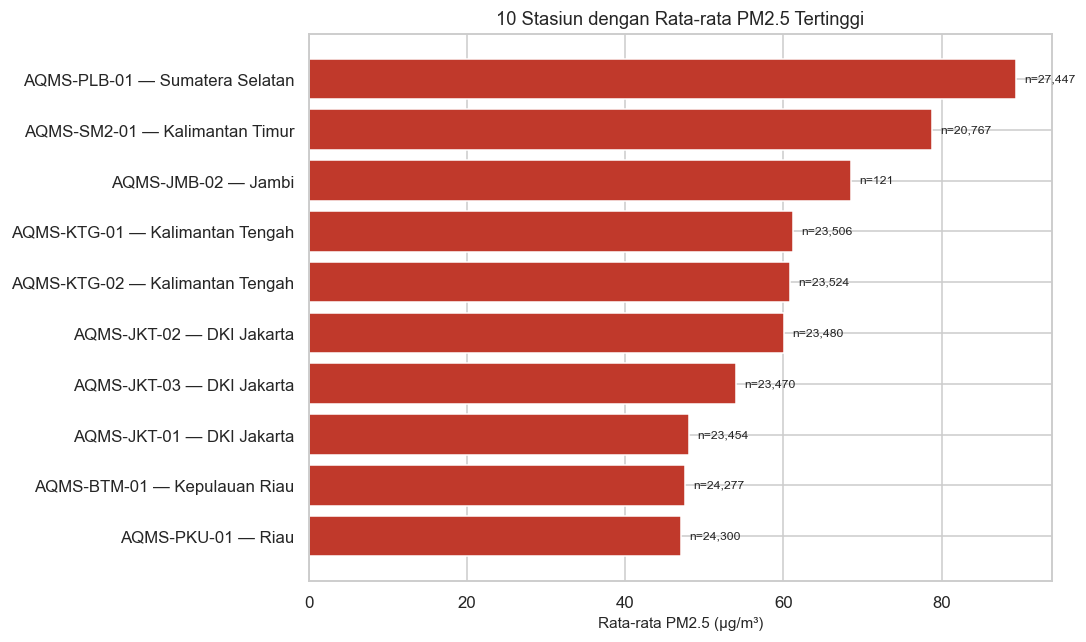

In [21]:
top10 = station_summary.head(10).iloc[::-1].copy()
top10["label"] = top10["station_code"] + " — " + top10["provinsi"]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top10["label"], top10["mean"], color="#c0392b")
for bar, n in zip(bars, top10["n"]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"n={n:,}", va="center", fontsize=8)
ax.set_title("10 Stasiun dengan Rata-rata PM2.5 Tertinggi")
ax.set_xlabel("Rata-rata PM2.5 (µg/m³)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "09_top_stasiun.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

,provinsi,n,mean,median,p95,n_station
17,Sumatera Selatan,27447,89.43,72.20,187.70,1
9,Kalimantan Timur,20767,78.84,47.81,256.45,1
8,Kalimantan Tengah,71315,55.67,24.70,143.40,3
3,DKI Jakarta,70404,54.07,53.67,70.02,3
10,Kepulauan Riau,24277,47.58,38.50,98.50,1
13,Riau,24300,47.09,35.30,110.60,1
4,Jambi,24384,44.57,32.40,109.40,2
2,D.I. Yogyakarta,24291,39.74,38.30,66.70,1
7,Kalimantan Barat,24298,38.21,22.30,118.50,1
14,Sulawesi Selatan,24265,36.83,36.20,58.20,1


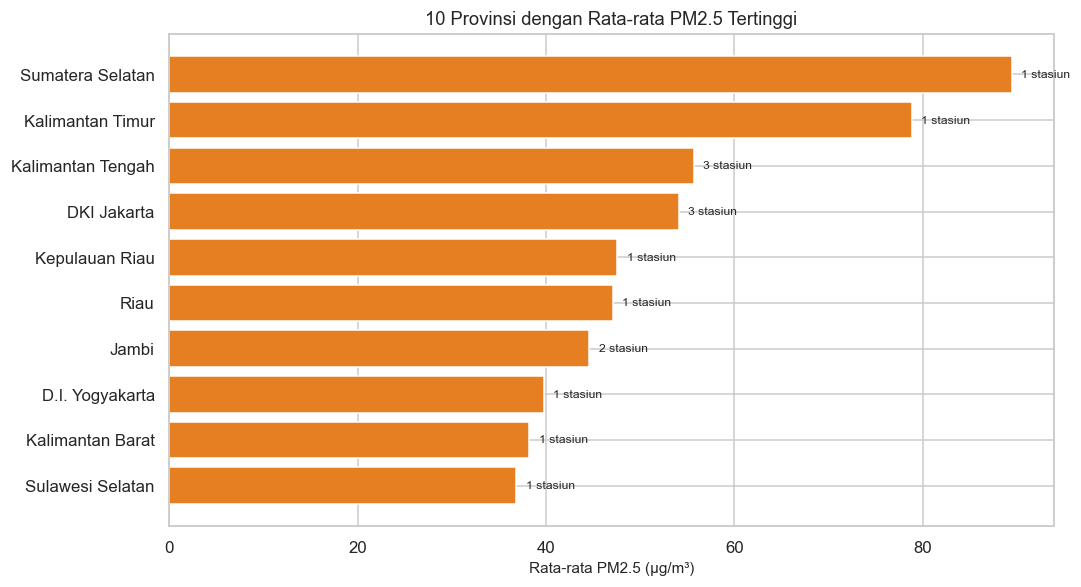

In [22]:
province_summary = (
    valid_pm.groupby("provinsi")
    .agg(
        n=("pm25_ug_m3", "size"),
        mean=("pm25_ug_m3", "mean"),
        median=("pm25_ug_m3", "median"),
        p95=("pm25_ug_m3", lambda s: s.quantile(0.95)),
        n_station=("station_code", "nunique"),
    )
    .reset_index()
    .sort_values("mean", ascending=False)
)
province_summary.to_csv(SUMMARY_DIR / "provinsi_summary.csv", index=False)
display(province_summary.head(10))

top_prov = province_summary.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(top_prov["provinsi"], top_prov["mean"], color="#e67e22")
for bar, n in zip(bars, top_prov["n_station"]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{n} stasiun", va="center", fontsize=8)
ax.set_title("10 Provinsi dengan Rata-rata PM2.5 Tertinggi")
ax.set_xlabel("Rata-rata PM2.5 (µg/m³)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_provinsi.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

,site_type,n,mean,median,n_station
11,Peatland Buffer / Urban Artery,27447,89.43,72.20,1
2,Industrial & Deforestation Buffer,20767,78.84,47.81,1
6,Peatland & Plantation Hinterland,121,68.60,68.58,1
7,Peatland Boundary,23524,60.84,24.87,1
4,Industrial Perimeter,23480,60.07,58.92,1
14,Urban Background,71251,49.58,41.50,3
5,Industrial Perimeter / Maritime,24277,47.58,38.50,1
10,Peatland Buffer / Urban,48563,45.77,33.70,2
8,Peatland Boundary / Airport,24285,45.28,24.30,1
9,Peatland Boundary / Inland,24298,38.21,22.30,1


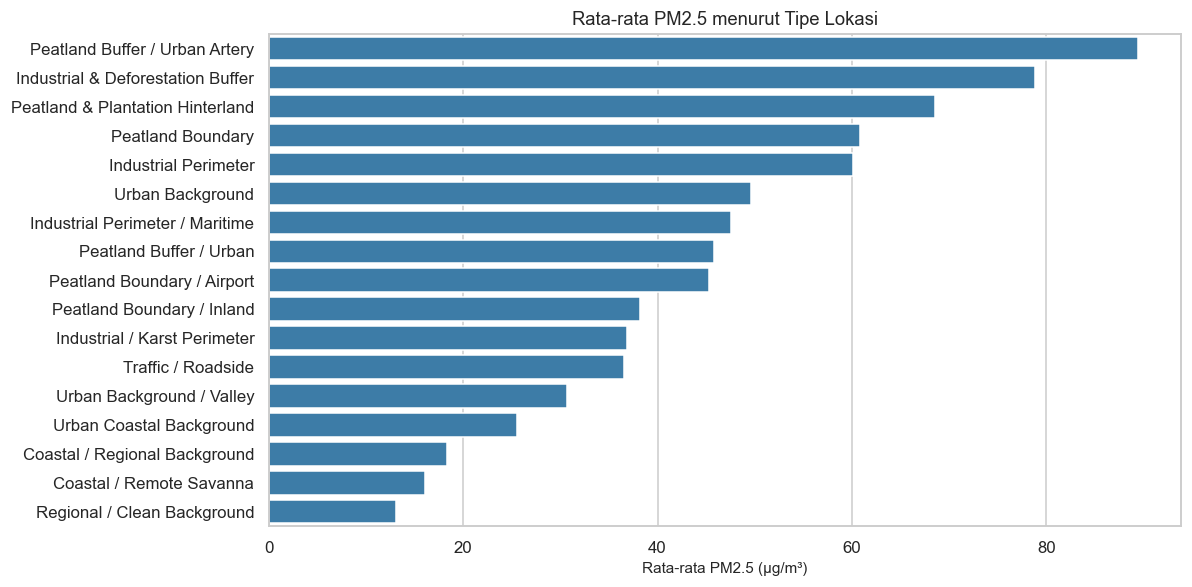

In [23]:
site_type_summary = (
    valid_pm.groupby("site_type")
    .agg(
        n=("pm25_ug_m3", "size"),
        mean=("pm25_ug_m3", "mean"),
        median=("pm25_ug_m3", "median"),
        n_station=("station_code", "nunique"),
    )
    .reset_index()
    .sort_values("mean", ascending=False)
)
site_type_summary.to_csv(SUMMARY_DIR / "tipe_lokasi_summary.csv", index=False)
display(site_type_summary)

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.barplot(data=site_type_summary, y="site_type", x="mean", ax=ax, color="#2c7fb8")
ax.set_title("Rata-rata PM2.5 menurut Tipe Lokasi")
ax.set_xlabel("Rata-rata PM2.5 (µg/m³)")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "11_tipe_lokasi.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

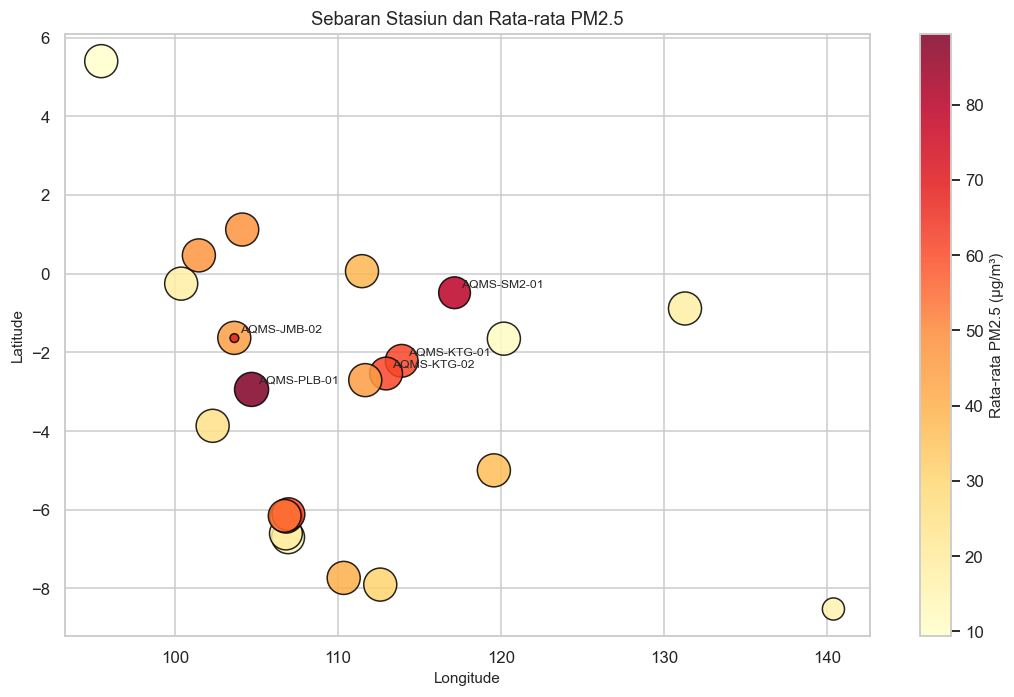

In [24]:
site_geo = (
    valid_pm.groupby(["site_key", "station_code", "provinsi"])
    .agg(
        mean=("pm25_ug_m3", "mean"),
        n=("pm25_ug_m3", "size"),
        lat=("latitude_dd", "first"),
        lon=("longitude_dd", "first"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 6.5))
sc = ax.scatter(
    site_geo["lon"], site_geo["lat"],
    c=site_geo["mean"], s=np.sqrt(site_geo["n"]) * 3,
    cmap="YlOrRd", edgecolor="black", alpha=0.85,
)
for _, r in site_geo.nlargest(5, "mean").iterrows():
    ax.annotate(r["station_code"], (r["lon"], r["lat"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
cb = fig.colorbar(sc, ax=ax)
cb.set_label("Rata-rata PM2.5 (µg/m³)")
ax.set_title("Sebaran Stasiun dan Rata-rata PM2.5")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.tight_layout()
fig.savefig(FIG_DIR / "12_peta_stasiun.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

**Catatan spasial.** Konsentrasi tidak tersebar merata. Beberapa stasiun memiliki rata-rata tinggi yang persisten, sedangkan stasiun lain tinggi karena episode ekstrem. Perbedaan rata-rata dan median membantu membedakan kedua pola tersebut.

## 7. Hubungan dengan Faktor Lingkungan

Korelasi dihitung pada level stasiun. Setiap titik mewakili satu stasiun, bukan satu observasi per jam.

In [25]:
site_features = (
    valid_pm.groupby(["site_key", "station_code", "provinsi", "site_type"])
    .agg(
        pm25=("pm25_ug_m3", "mean"),
        traffic=("traffic_intensity_per_h", "first"),
        distance=("distance_to_road_m", "first"),
        temperature=("temperature_c", "mean"),
        humidity=("humidity_pct", "mean"),
        wind=("wind_speed_ms", "mean"),
        baseline=("baseline_pm25", "first"),
        n=("pm25_ug_m3", "size"),
    )
    .reset_index()
)

corr_vars = ["pm25", "traffic", "distance", "temperature", "humidity", "wind", "baseline"]
pearson = site_features[corr_vars].corr(method="pearson")
spearman = site_features[corr_vars].corr(method="spearman")

driver_corr = pd.DataFrame({
    "variable": [v for v in corr_vars if v != "pm25"],
    "pearson": [pearson.loc["pm25", v] for v in corr_vars if v != "pm25"],
    "spearman": [spearman.loc["pm25", v] for v in corr_vars if v != "pm25"],
})
driver_corr.to_csv(SUMMARY_DIR / "korelasi_driver.csv", index=False)
display(driver_corr)
display(site_features.sort_values("pm25", ascending=False).head(10))

,variable,pearson,spearman
0,traffic,0.40,0.45
1,distance,-0.57,-0.55
2,temperature,0.46,0.39
3,humidity,-0.16,-0.23
4,wind,-0.44,-0.20
5,baseline,0.73,0.77


,site_key,station_code,provinsi,site_type,pm25,traffic,distance,temperature,humidity,wind,baseline,n
18,LOC-PLB-01,AQMS-PLB-01,Sumatera Selatan,Peatland Buffer / Urban Artery,89.43,"1,950.00",30.00,26.44,78.49,1.90,42.00,27447
20,LOC-SM2-01,AQMS-SM2-01,Kalimantan Timur,Industrial & Deforestation Buffer,78.84,"1,650.00",40.00,25.46,86.74,1.81,32.50,20767
9,LOC-JMB-02,AQMS-JMB-02,Jambi,Peatland & Plantation Hinterland,68.60,350.00,65.00,29.58,77.62,2.56,68.90,121
11,LOC-KTG-01,AQMS-KTG-01,Kalimantan Tengah,Urban Background,61.23,450.00,60.00,29.03,78.82,1.40,22.00,23506
12,LOC-KTG-02,AQMS-KTG-02,Kalimantan Tengah,Peatland Boundary,60.84,850.00,30.00,29.03,78.83,1.40,35.00,23524
6,LOC-JKT-02,AQMS-JKT-02,DKI Jakarta,Industrial Perimeter,60.07,"1,400.00",25.00,28.65,75.73,2.39,55.00,23480
7,LOC-JKT-03,AQMS-JKT-03,DKI Jakarta,Traffic / Roadside,54.06,"3,200.00",6.00,28.64,75.77,2.40,39.00,23470
5,LOC-JKT-01,AQMS-JKT-01,DKI Jakarta,Urban Background,48.09,"1,850.00",45.00,28.64,75.75,2.40,37.50,23454
3,LOC-BTM-01,AQMS-BTM-01,Kepulauan Riau,Industrial Perimeter / Maritime,47.58,"2,200.00",25.00,25.83,78.46,2.34,38.00,24277
17,LOC-PKU-01,AQMS-PKU-01,Riau,Peatland Buffer / Urban,47.09,"1,800.00",35.00,25.83,78.44,2.35,35.00,24300


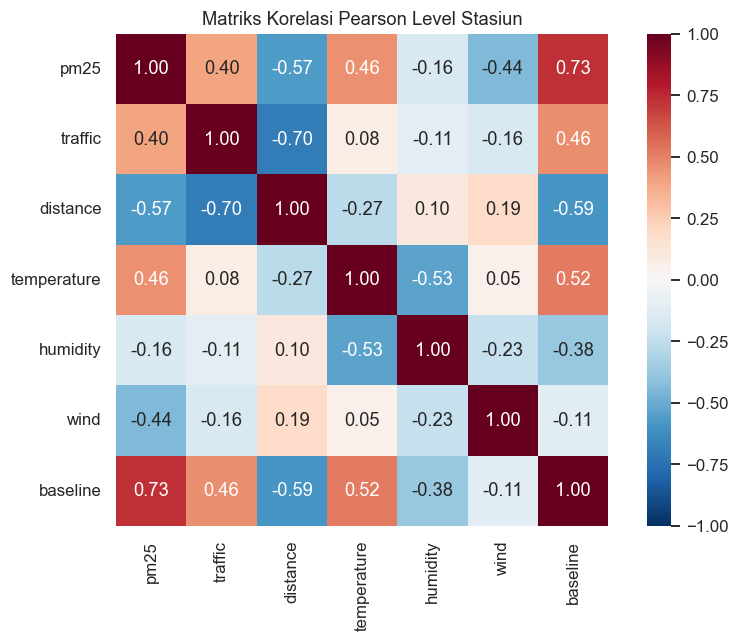

In [26]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    pearson, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    vmin=-1, vmax=1, square=True, ax=ax,
)
ax.set_title("Matriks Korelasi Pearson Level Stasiun")
fig.tight_layout()
fig.savefig(FIG_DIR / "13_korelasi_driver.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

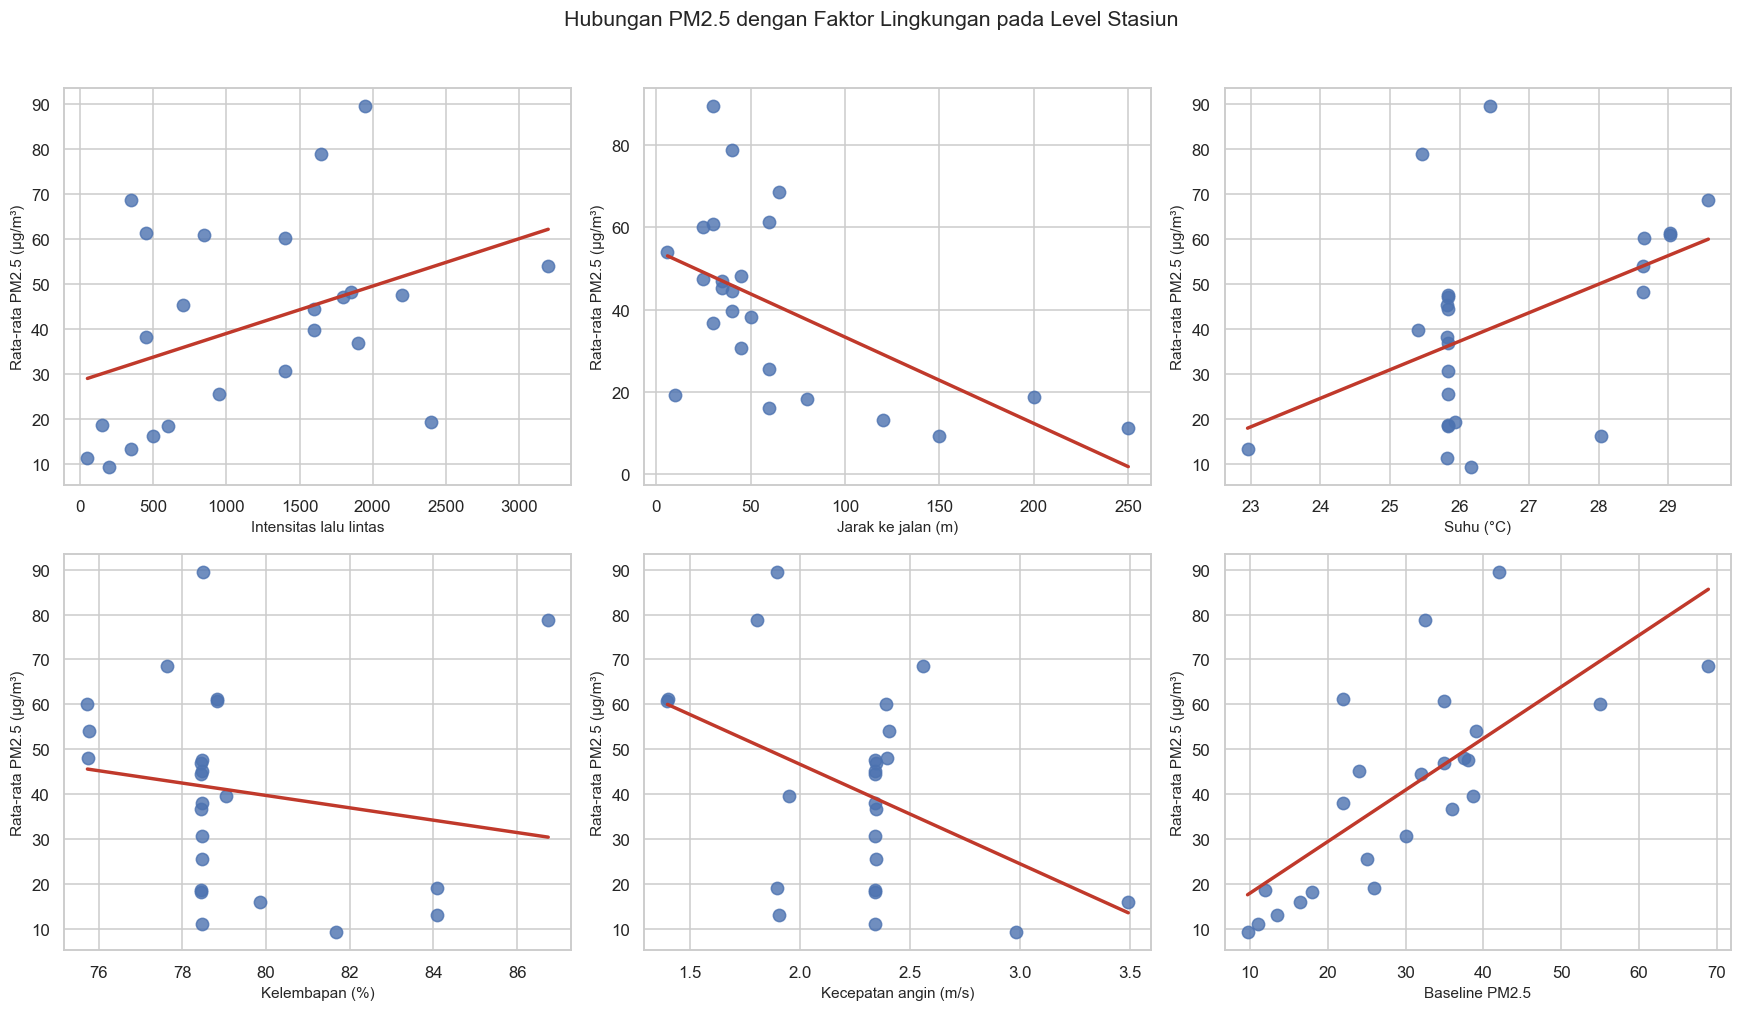

In [27]:
plot_vars = [
    ("traffic", "Intensitas lalu lintas"),
    ("distance", "Jarak ke jalan (m)"),
    ("temperature", "Suhu (°C)"),
    ("humidity", "Kelembapan (%)"),
    ("wind", "Kecepatan angin (m/s)"),
    ("baseline", "Baseline PM2.5"),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (var, label) in zip(axes.ravel(), plot_vars):
    sns.regplot(
        data=site_features, x=var, y="pm25", ax=ax,
        scatter_kws={"s": 65, "alpha": 0.8},
        line_kws={"color": "#c0392b"}, ci=None,
    )
    ax.set_xlabel(label)
    ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
fig.suptitle("Hubungan PM2.5 dengan Faktor Lingkungan pada Level Stasiun", y=1.02, fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "14_scatter_driver.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

**Catatan hubungan.** Korelasi level stasiun menunjukkan arah asosiasi, bukan efek kausal. Lalu lintas dan jarak ke jalan bergerak sesuai arah yang dapat dijelaskan secara deskriptif, tetapi faktor musim, geografi, dan atmosfer tidak dipisahkan dalam analisis ini.

## 8. Indikator Kesehatan

Bagian ini merangkum volume outcome, komposisi usia, pola bulanan, dan korelasi agregat dengan PM2.5 pada level provinsi-bulan.

Total respirasi          : 733,191
Respirasi < 5 tahun      : 186,167 (25.4%)
Respirasi > 60 tahun     : 225,117 (30.7%)
Gabungan balita + lansia : 411,284 (56.1%)


,provinsi,resp,under5,over60
3,DKI Jakarta,"166,544.00","41,872.00","52,724.00"
9,Kalimantan Tengah,"115,656.00","27,968.00","32,164.00"
5,Jawa Barat,"43,917.00","5,773.00","7,836.00"
19,Sumatera Selatan,"43,292.00","12,740.00","15,093.00"
12,Lampung,"35,639.00","10,281.00","12,363.00"
4,Jambi,"32,091.00","9,252.00","10,954.00"
2,D.I. Yogyakarta,"30,498.00","8,195.00","9,849.00"
11,Kepulauan Riau,"28,937.00","8,207.00","9,657.00"
15,Riau,"28,543.00","8,115.00","9,567.00"
7,Kalimantan Barat,"26,222.00","7,175.00","8,596.00"


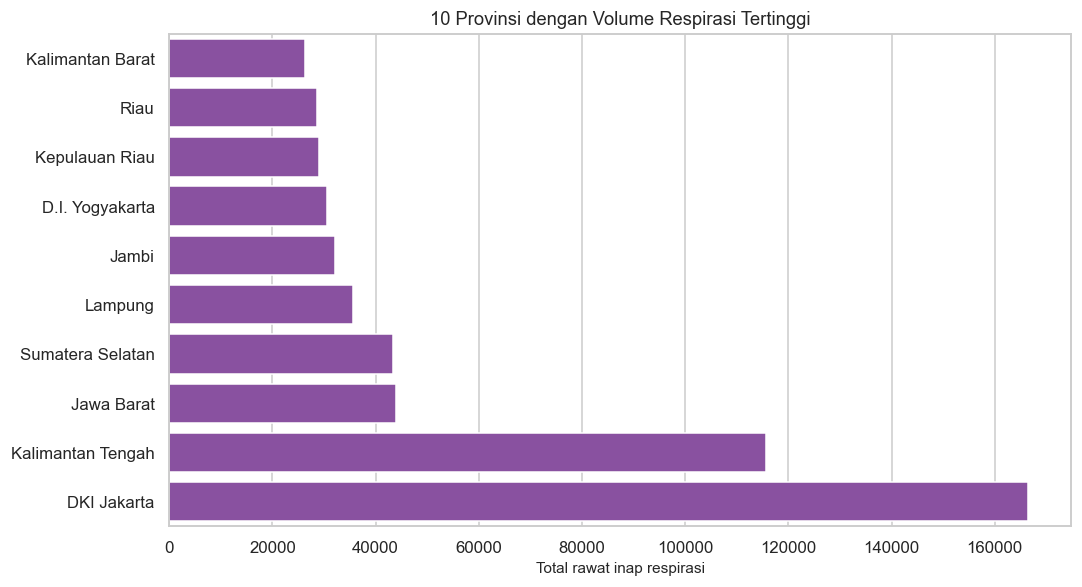

In [28]:
under5 = health["resp_admissions_under5"].sum()
over60 = health["resp_admissions_over60"].sum()
resp_total = health["resp"].sum()

print(f"Total respirasi          : {resp_total:,.0f}")
print(f"Respirasi < 5 tahun      : {under5:,.0f} ({under5 / resp_total:.1%})")
print(f"Respirasi > 60 tahun     : {over60:,.0f} ({over60 / resp_total:.1%})")
print(f"Gabungan balita + lansia : {under5 + over60:,.0f} ({(under5 + over60) / resp_total:.1%})")

province_health = (
    health.groupby("provinsi")
    .agg(
        resp=("resp", "sum"),
        under5=("resp_admissions_under5", "sum"),
        over60=("resp_admissions_over60", "sum"),
    )
    .reset_index()
    .sort_values("resp", ascending=False)
)
province_health.to_csv(SUMMARY_DIR / "provinsi_health_summary.csv", index=False)
display(province_health.head(10))

top_h = province_health.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=top_h, y="provinsi", x="resp", ax=ax, color="#8e44ad")
ax.set_title("10 Provinsi dengan Volume Respirasi Tertinggi")
ax.set_xlabel("Total rawat inap respirasi")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIG_DIR / "15_provinsi_respirasi.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

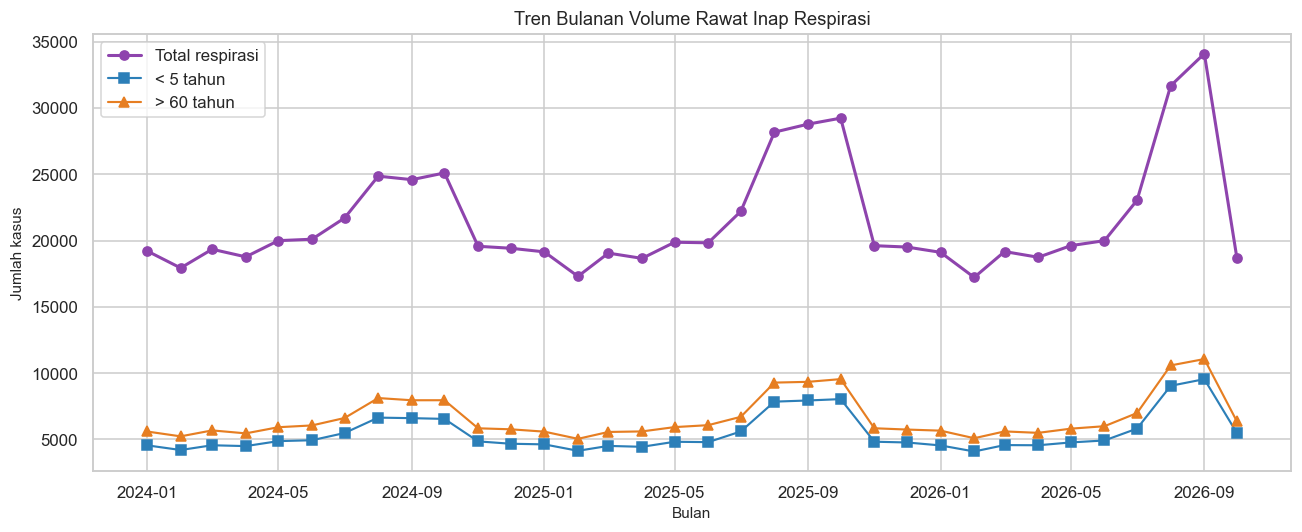

In [29]:
health_monthly = (
    health[health["month_start"] >= pd.Timestamp("2024-01-01")]
    .groupby("month_start")
    .agg(
        resp=("resp", "sum"),
        under5=("resp_admissions_under5", "sum"),
        over60=("resp_admissions_over60", "sum"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(health_monthly["month_start"], health_monthly["resp"], marker="o", linewidth=2, label="Total respirasi", color="#8e44ad")
ax.plot(health_monthly["month_start"], health_monthly["under5"], marker="s", linewidth=1.4, label="< 5 tahun", color="#2c7fb8")
ax.plot(health_monthly["month_start"], health_monthly["over60"], marker="^", linewidth=1.4, label="> 60 tahun", color="#e67e22")
ax.set_title("Tren Bulanan Volume Rawat Inap Respirasi")
ax.set_xlabel("Bulan")
ax.set_ylabel("Jumlah kasus")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "16_tren_respirasi.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

n pasangan provinsi-bulan : 612
Pearson  : 0.395 (p=2.58e-24)
Spearman : 0.594 (p=1.51e-59)


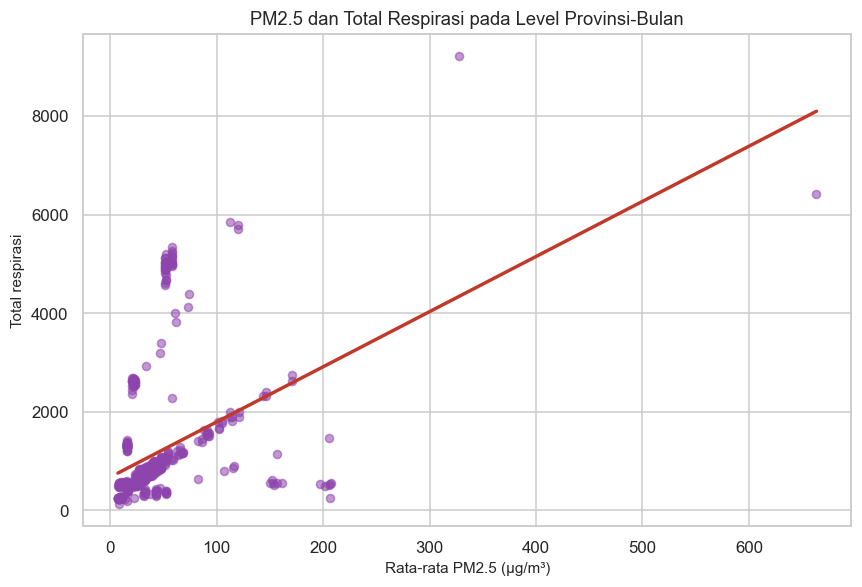

In [30]:
pm_prov_month = (
    valid_pm.groupby(["provinsi", "month_start"])
    .agg(pm25=("pm25_ug_m3", "mean"), n_pm=("pm25_ug_m3", "size"))
    .reset_index()
)
health_prov_month = (
    health.groupby(["provinsi", "month_start"])
    .agg(
        resp=("resp", "sum"),
        under5=("resp_admissions_under5", "sum"),
        over60=("resp_admissions_over60", "sum"),
    )
    .reset_index()
)
prov_month = pm_prov_month.merge(health_prov_month, on=["provinsi", "month_start"], how="inner")
prov_month.to_csv(SUMMARY_DIR / "provinsi_bulan_summary.csv", index=False)

r_p, p_p = pearsonr(prov_month["pm25"], prov_month["resp"])
r_s, p_s = spearmanr(prov_month["pm25"], prov_month["resp"])
print(f"n pasangan provinsi-bulan : {len(prov_month):,}")
print(f"Pearson  : {r_p:.3f} (p={p_p:.3g})")
print(f"Spearman : {r_s:.3f} (p={p_s:.3g})")

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.regplot(
    data=prov_month, x="pm25", y="resp", ax=ax,
    scatter_kws={"s": 28, "alpha": 0.55, "color": "#8e44ad"},
    line_kws={"color": "#c0392b"}, ci=None,
)
ax.set_title("PM2.5 dan Total Respirasi pada Level Provinsi-Bulan")
ax.set_xlabel("Rata-rata PM2.5 (µg/m³)")
ax.set_ylabel("Total respirasi")
fig.tight_layout()
fig.savefig(FIG_DIR / "17_provinsi_bulan_kesehatan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

In [31]:
prov_month_full = prov_month[
    ~((prov_month["month_start"].dt.year == 2026) & (prov_month["month_start"].dt.month == 10))
]
r_pf, p_pf = pearsonr(prov_month_full["pm25"], prov_month_full["resp"])
r_sf, p_sf = spearmanr(prov_month_full["pm25"], prov_month_full["resp"])
print("Tanpa Oktober 2026 parsial")
print(f"n        : {len(prov_month_full):,}")
print(f"Pearson  : {r_pf:.3f} (p={p_pf:.3g})")
print(f"Spearman : {r_sf:.3f} (p={p_sf:.3g})")

pm_nat = valid_pm.groupby("month_start")["pm25_ug_m3"].mean().reset_index(name="pm25")
health_nat = health.groupby("month_start")["resp"].sum().reset_index(name="resp")
nat = pm_nat.merge(health_nat, on="month_start", how="inner")
nat = nat[nat["month_start"] < pd.Timestamp("2026-10-01")].copy()

r_n, p_n = pearsonr(nat["pm25"], nat["resp"])
r_ns, p_ns = spearmanr(nat["pm25"], nat["resp"])
print("\nNasional-bulan (bulan penuh)")
print(f"n        : {len(nat):,}")
print(f"Pearson  : {r_n:.3f} (p={p_n:.3g})")
print(f"Spearman : {r_ns:.3f} (p={p_ns:.3g})")

Tanpa Oktober 2026 parsial
n        : 594
Pearson  : 0.396 (p=1.03e-23)
Spearman : 0.604 (p=1.87e-60)

Nasional-bulan (bulan penuh)
n        : 33
Pearson  : 0.974 (p=1.37e-21)
Spearman : 0.941 (p=4.05e-16)


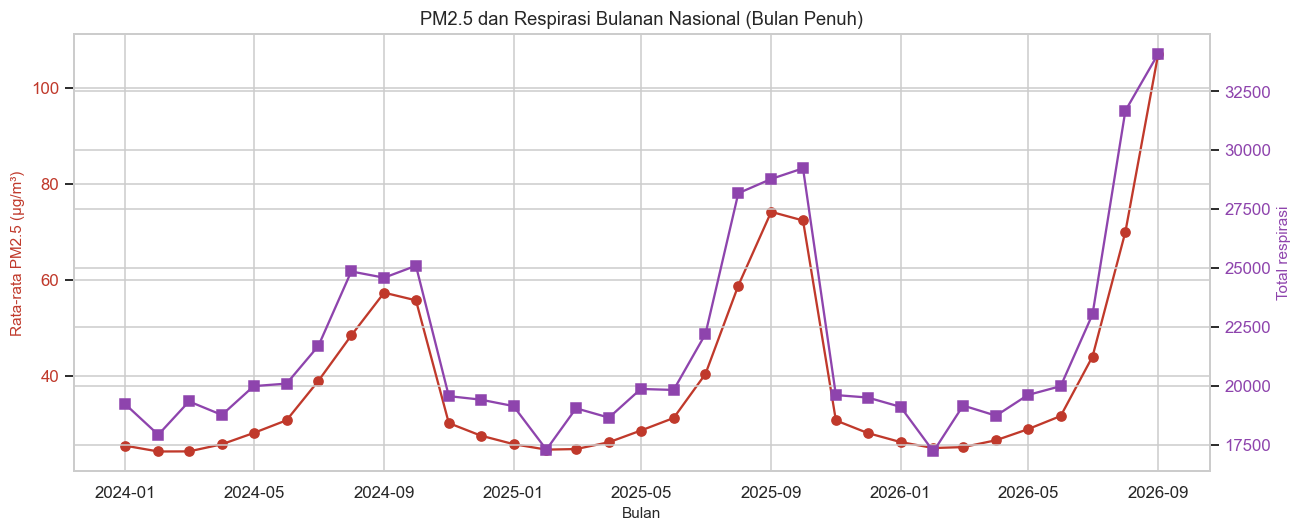

In [32]:
nat_plot = nat.copy()
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(nat_plot["month_start"], nat_plot["pm25"], marker="o", color="#c0392b", label="PM2.5")
ax1.set_xlabel("Bulan")
ax1.set_ylabel("Rata-rata PM2.5 (µg/m³)", color="#c0392b")
ax1.tick_params(axis="y", labelcolor="#c0392b")

ax2 = ax1.twinx()
ax2.plot(nat_plot["month_start"], nat_plot["resp"], marker="s", color="#8e44ad", label="Respirasi")
ax2.set_ylabel("Total respirasi", color="#8e44ad")
ax2.tick_params(axis="y", labelcolor="#8e44ad")

ax1.set_title("PM2.5 dan Respirasi Bulanan Nasional (Bulan Penuh)")
fig.tight_layout()
fig.savefig(FIG_DIR / "18_nasional_bulan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

**Catatan kesehatan.** Volume kasus bukan prevalensi atau insidensi karena tidak ada denominator populasi. Korelasi provinsi-bulan merupakan korelasi ekologis; korelasi nasional-bulan yang lebih tinggi sangat dipengaruhi agregasi, musim, dan pola pelaporan.

## 9. Eksplorasi Lag 0–3 Bulan

Analisis lag dilakukan pada level provinsi-bulan dengan menghubungkan rata-rata PM2.5 pada bulan sebelumnya dengan total respirasi bulan berjalan. Bagian ini bersifat eksploratif dan tidak digunakan untuk klaim kausal.

,lag_bulan,n,pearson,p_pearson,spearman,p_spearman
0,0,612,0.40,0.00,0.59,0.00
1,1,594,0.32,0.00,0.55,0.00
2,2,576,0.23,0.00,0.49,0.00
3,3,558,0.17,0.00,0.43,0.00


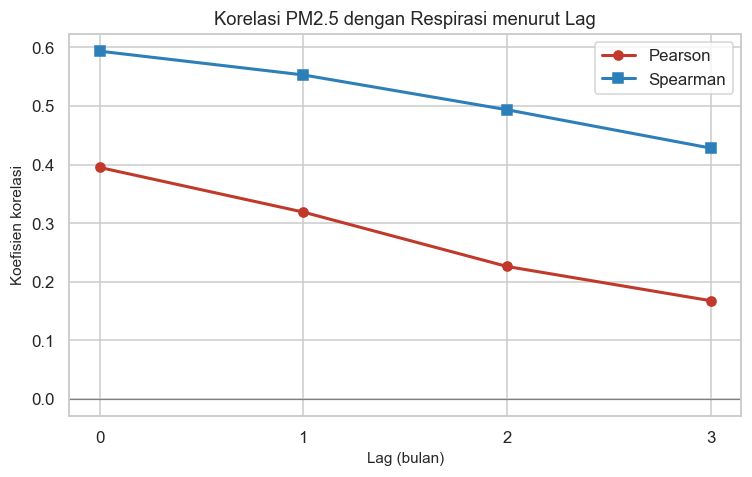

In [33]:
prov_month_lag = prov_month.sort_values(["provinsi", "month_start"]).copy()

lag_rows = []
for lag in range(0, 4):
    col = f"pm25_lag{lag}"
    prov_month_lag[col] = prov_month_lag.groupby("provinsi")["pm25"].shift(lag)
    tmp = prov_month_lag.dropna(subset=[col, "resp"]).copy()
    r, p = pearsonr(tmp[col], tmp["resp"])
    rho, p2 = spearmanr(tmp[col], tmp["resp"])
    lag_rows.append({
        "lag_bulan": lag,
        "n": len(tmp),
        "pearson": r,
        "p_pearson": p,
        "spearman": rho,
        "p_spearman": p2,
    })

lag_df = pd.DataFrame(lag_rows)
lag_df.to_csv(SUMMARY_DIR / "lag_correlation.csv", index=False)
display(lag_df)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(lag_df["lag_bulan"], lag_df["pearson"], marker="o", linewidth=2, label="Pearson", color="#c0392b")
ax.plot(lag_df["lag_bulan"], lag_df["spearman"], marker="s", linewidth=2, label="Spearman", color="#2c7fb8")
ax.set_title("Korelasi PM2.5 dengan Respirasi menurut Lag")
ax.set_xlabel("Lag (bulan)")
ax.set_ylabel("Koefisien korelasi")
ax.set_xticks(lag_df["lag_bulan"])
ax.axhline(0, color="grey", linewidth=0.8)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "19_lag_korelasi.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 10. Sintesis dan Keterbatasan

EDA menunjukkan distribusi polutan yang dipengaruhi nilai ekstrem, pola musiman yang kuat, variasi jam yang lebih menonjol daripada hari, heterogenitas geografis, serta asosiasi dengan faktor lingkungan dan indikator kesehatan.

**Keterbatasan utama**
- Dataset sintetis, sehingga temuan bukan representasi kondisi aktual Indonesia.
- Analisis bersifat observasional dan asosiatif; tidak ada inferensi kausal.
- Indikator kesehatan berupa volume tanpa denominator populasi.
- Tidak ada pemetaan resmi stasiun AQMS–rumah sakit; analisis gabungan berada pada level provinsi-bulan.
- Tiga stasiun tidak memiliki PM2.5 valid dan satu stasiun memiliki jumlah observasi sangat kecil.
- Oktober 2026 hanya mencakup 1–14 Oktober.
- Eksplorasi lag bersifat tambahan dan belum mengontrol confounding.

In [34]:
key_metrics = pd.DataFrame([
    {"metric": "total observasi AQMS", "value": len(aq)},
    {"metric": "observasi VALID", "value": int(aq["is_qc_valid"].sum())},
    {"metric": "observasi PM2.5 numerik VALID", "value": len(valid_pm)},
    {"metric": "jumlah stasiun PM2.5 valid", "value": valid_pm["site_key"].nunique()},
    {"metric": "jumlah provinsi PM2.5 valid", "value": valid_pm["provinsi"].nunique()},
    {"metric": "rata-rata PM2.5", "value": valid_pm["pm25_ug_m3"].mean()},
    {"metric": "median PM2.5", "value": valid_pm["pm25_ug_m3"].median()},
    {"metric": "P95 PM2.5", "value": valid_pm["pm25_ug_m3"].quantile(0.95)},
    {"metric": "rata-rata PM10", "value": valid_pm["pm10_ug_m3"].mean()},
    {"metric": "median PM10", "value": valid_pm["pm10_ug_m3"].median()},
    {"metric": "P95 PM10", "value": valid_pm["pm10_ug_m3"].quantile(0.95)},
    {"metric": "total respirasi", "value": resp_total},
    {"metric": "pasangan provinsi-bulan", "value": len(prov_month)},
    {"metric": "korelasi Pearson provinsi-bulan", "value": r_p},
    {"metric": "korelasi Spearman provinsi-bulan", "value": r_s},
])
key_metrics.to_csv(SUMMARY_DIR / "eda_key_metrics.csv", index=False)
display(key_metrics)
print("\nSelesai. Figure tersimpan di:", FIG_DIR)
print("Tabel ringkasan tersimpan di:", SUMMARY_DIR)

,metric,value
0,total observasi AQMS,"667,844.00"
1,observasi VALID,"599,179.00"
2,observasi PM2.5 numerik VALID,"533,813.00"
3,jumlah stasiun PM2.5 valid,24.00
4,jumlah provinsi PM2.5 valid,18.00
5,rata-rata PM2.5,40.57
6,median PM2.5,28.17
7,P95 PM2.5,109.80
8,rata-rata PM10,58.77
9,median PM10,41.60



Selesai. Figure tersimpan di: figures
Tabel ringkasan tersimpan di: data/eda_summary
